# Virtual angles, drawn and checked

Each quantity below is defined from lab vectors of one position
([docs/virtual_angles.md](../docs/virtual_angles.md)), drawn for a real
solution, and compared with diffcalc's `get_virtual_angles` for that
position. Then each is *held* as a constraint and the solutions checked.

In [1]:
import sys, os, logging, warnings
sys.path.insert(0, os.path.abspath("../src"))      # hklforge from this repository
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hklforge import Diffractometer, Geometry, ModeError, Degenerate
from hklforge.lattice import b_matrix
from hklforge.draw import draw, draw_circles
logging.getLogger("diffcalc").setLevel(logging.ERROR)
pd.set_option("display.precision", 3)
%matplotlib inline

In [2]:
from diffcalc.ub.calc import UBCalculation
from diffcalc.hkl.calc import HklCalculation
from diffcalc.hkl.constraints import Constraints
from diffcalc.hkl.geometry import Position
from diffcalc.util import DiffcalcException

import contextlib, io

def diffcalc_ubcalc(lattice, U=np.eye(3), surface=None, reference=None):
    ubc = UBCalculation("example")
    ubc.set_lattice("x", *lattice)
    with contextlib.redirect_stdout(io.StringIO()):     # diffcalc prints "Calculating UB matrix."
        ubc.set_u(U)
    if surface is not None:
        ubc.surf_nphi = tuple(np.asarray(surface) / np.linalg.norm(surface))
    if reference is not None:
        ubc.n_phi = tuple(np.asarray(reference) / np.linalg.norm(reference))
    return ubc

def diffcalc_solve(ubc, hkl, mode, wavelength):
    """diffcalc's positions as dicts, [] if it finds none, or the error text."""
    try:
        return [p.asdict for p, _ in HklCalculation(ubc, Constraints(mode)).get_position(*hkl, wavelength)]
    except DiffcalcException as e:
        msg = " ".join(str(e).replace("*", " ").split())
        if "No solutions" in msg or "prohibits a solution" in msg:
            return []
        return msg
    except (AssertionError, ValueError) as e:
        return f"{type(e).__name__}: {e}"

def same(a, b, tol=1e-5):
    return all(abs((a[n] - b[n] + 180) % 360 - 180) < tol for n in a)

def same_set(xs, ys):
    return all(any(same(x, y) for y in ys) for x in xs) and all(any(same(y, x) for x in xs) for y in ys)

In [3]:
psic = Geometry.builtin("psic")
lattice = (4.0, 4.0, 4.0, 90, 90, 90)
ub = b_matrix(*lattice)
d = Diffractometer(psic, ub, energy=9000, surface_hkl=(0, 0, 1), reference_hkl=(0, -1, 1))
ubc = diffcalc_ubcalc(lattice, surface=ub @ (0, 0, 1), reference=ub @ (0, -1, 1))
pos = min(d.solve((1, 1, 2), {"mu": 10, "nu": 20, "betain": 5}), key=lambda a: abs(a["eta"]) + abs(a["chi"]))
print(pos)
mine = d.pseudo(pos)
theirs = HklCalculation(ubc, Constraints({})).get_virtual_angles(Position(**pos))
pd.DataFrame({"hklforge": mine, "diffcalc": theirs}).assign(
    difference=lambda t: (t.hklforge - t.diffcalc + 180) % 360 - 180)

{'mu': 10.0, 'eta': -3.707453283881108, 'chi': 41.74739311487974, 'phi': 91.98901753005111, 'nu': 20.0, 'delta': 46.724598270418085}


,hklforge,diffcalc,difference
theta,24.948,24.948,0.0
ttheta,49.897,49.897,0.0
qaz,72.150,72.150,0.0
betain,5.000,5.000,0.0
betaout,36.988,36.988,0.0
alpha,8.789,8.789,0.0
beta,5.206,5.206,0.0
naz,-3.358,-3.358,0.0
tau,73.221,73.221,0.0
psi,92.048,92.048,0.0


`omega` is hklforge's (diffcalc has it only as a constraint). All others agree to ~1e-13 deg.

## 2θ: b, k', Q and the scattering plane
cos 2θ = b·k'. Q = |k|(k' − b) makes 90° + θ with the beam - that is the Bragg condition.

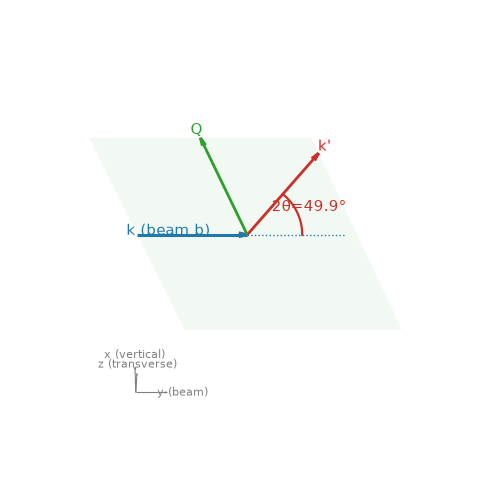

In [4]:
draw(d, pos, show=("ttheta",), view="plane");

## qaz, naz: azimuths about the beam
Looking downstream. r = z (azimuth 0), u = x (90°, vertical); qaz is the azimuth of k' (the
scattering plane), naz that of the reference vector n.

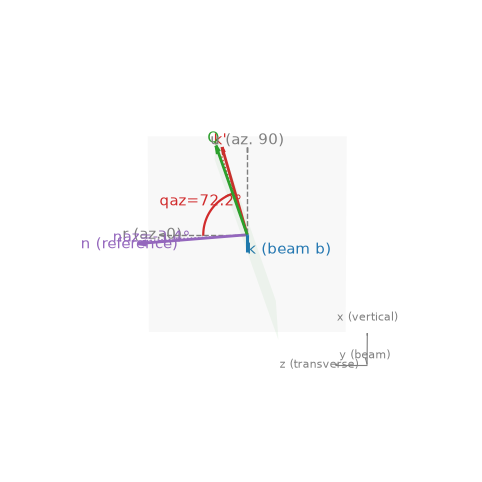

In [5]:
draw(d, pos, show=("qaz", "naz"), view="beam");

## alpha, beta / betain, betaout: beams to a plane
sin α = −b·n, sin β = k'·n (reference vector); betain / betaout the same with the surface
normal. Drawn here with n = surface normal = (0 0 1) so the plane is the surface.

{'betain': 10.0, 'betaout': 31.008, 'alpha': 10.0, 'beta': 31.008}


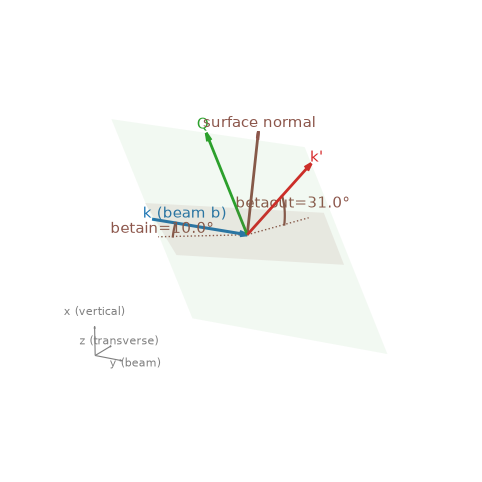

In [6]:
d_up = Diffractometer(psic, ub, energy=9000, surface_hkl=(0, 0, 1), reference_hkl=(0, 0, 1))
p_up = min(d_up.solve((1, 1, 2), {"mu": 0, "nu": 0, "betain": 10}), key=lambda a: abs(a["eta"]) + abs(a["chi"]))
draw(d_up, p_up, show=("betain", "betaout"));
print({k: round(v, 3) for k, v in d_up.pseudo(p_up).items() if k in ("betain", "betaout", "alpha", "beta")})

Because k' = b + Q/|k|: sin β = −sin α + Q·n/|k|. The exit angle is fixed by the incidence
angle and hkl - which is why only one of them can be held:

In [7]:
Q = psic.q_lab(p_up, d_up.k); n = psic.sample_matrix(p_up) @ d_up.surface
va = d_up.pseudo(p_up)
print(np.sin(np.radians(va["betaout"])), -np.sin(np.radians(va["betain"])) + Q @ n / d_up.k)

0.5151529247397377 0.5151529247397377


## tau and psi: n about Q
cos τ = Q̂·n (fixed by the crystal). ψ is the azimuth of n about Q, from p - the direction
in the scattering plane normal to Q, along the beam's travel.

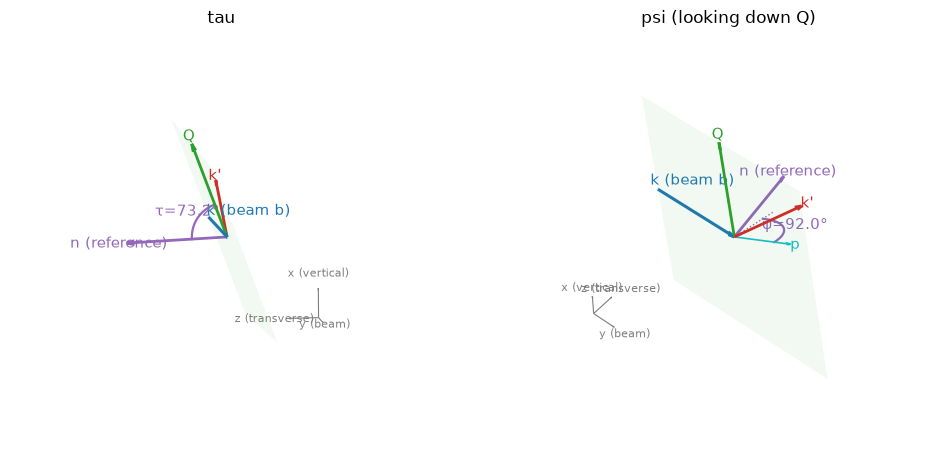

In [8]:
fig = plt.figure(figsize=(12, 5.5))
draw(d, pos, show=("tau",), view="Qn", ax=fig.add_subplot(1, 2, 1, projection="3d"), title="tau")
draw(d, pos, show=("psi",), view="Q", ax=fig.add_subplot(1, 2, 2, projection="3d"), title="psi (looking down Q)");

## omega and bisect: the chi axis
`bisect`: the chi axis lies in the scattering plane. `omega`: its direction there, from p towards Q.
omega = 0 with bisect is the classic bisecting position (chi axis normal to Q).

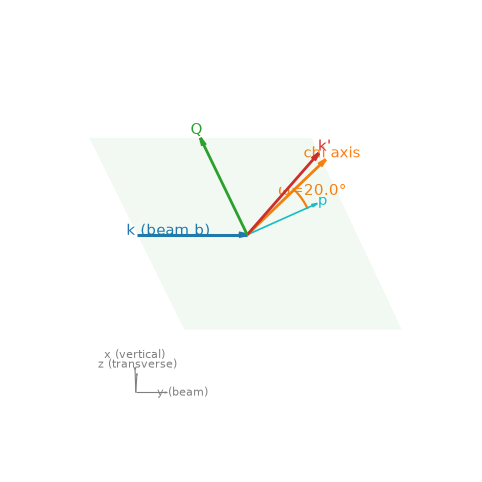

In [9]:
pb = min(d.solve((1, 1, 2), {"nu": 20, "bisect": True, "omega": 20}), key=lambda a: abs(a["eta"]) + abs(a["chi"]))
draw(d, pb, show=("omega",), view="plane");

## Holding each virtual angle

For each constraint, a mode holding it (plus circles), all solutions, and the value each
solution has - it must equal what was asked for.

In [10]:
tests = [
    ({"chi": 10, "phi": 20, "betain": 3}, "betain"),
    ({"chi": 10, "phi": 20, "betaout": 3}, "betaout"),
    ({"mu": 0, "nu": 0, "alpha": 4}, "alpha"),
    ({"mu": 0, "nu": 0, "beta": 4}, "beta"),
    ({"mu": 0, "nu": 0, "psi": 60}, "psi"),
    ({"qaz": 90, "mu": 0, "phi": 0}, "qaz"),
    ({"naz": 30, "alpha": 5, "phi": 0}, "naz"),
    ({"nu": 0, "bisect": True, "omega": 15}, "omega"),
]
rows = []
for m, name in tests:
    sols = d.solve((1, 1, 2), m)
    vals = [d.pseudo(s)[name] for s in sols]
    theirs = diffcalc_solve(ubc, (1, 1, 2), m, d.wavelength)
    rows.append({"mode": m, "held": f"{name} = {m[name]}", "solutions": len(sols),
                 "values found": sorted({round(v, 9) for v in vals}),
                 "diffcalc": theirs if isinstance(theirs, str) else len(theirs)})
pd.DataFrame(rows)

,mode,held,solutions,values found,diffcalc
0,"{'chi': 10, 'phi': 20, 'betain': 3}",betain = 3,8,[3.0],8
1,"{'chi': 10, 'phi': 20, 'betaout': 3}",betaout = 3,8,[3.0],8
2,"{'mu': 0, 'nu': 0, 'alpha': 4}",alpha = 4,8,[4.0],8
3,"{'mu': 0, 'nu': 0, 'beta': 4}",beta = 4,8,[4.0],8
4,"{'mu': 0, 'nu': 0, 'psi': 60}",psi = 60,4,[60.0],4
5,"{'qaz': 90, 'mu': 0, 'phi': 0}",qaz = 90,4,[90.0],4
6,"{'naz': 30, 'alpha': 5, 'phi': 0}",naz = 30,8,[30.0],8
7,"{'nu': 0, 'bisect': True, 'omega': 15}",omega = 15,8,[15.0],8


(diffcalc's count for omega includes positions that violate the mode -
[03](03_diffcalc_comparison.ipynb).)